# Day 20 — Transaction Measurement Verification and Outcome Feasibility

## Objective

The objective of Day 20 is to investigate transaction measurement conventions and assess whether a reliable customer-level expenditure outcome can be constructed for causal analysis.

## Research Questions

1. What do quantity and selling_price represent?
2. Are selling prices recorded per unit or per transaction?
3. How are other_discount and coupon_discount calculated?
4. Can actual customer expenditure be reliably estimated?
5. Is the constructed outcome suitable for causal inference?
6. Does the available dataset support Double Machine Learning?

## Expected Outputs

- Transaction variable definition assessment.
- Selling price measurement assessment.
- Discount calculation validation.
- Expenditure feasibility assessment.
- Customer-level outcome assessment.
- Final research recommendation.

## Important Research Principle

A mathematically calculated spending variable is not automatically a valid expenditure measure.

Variable definitions, measurement conventions, and causal assumptions must be verified before selecting the final outcome.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load transaction dataset
transaction_data = pd.read_csv(
    "../data/raw/customer_transaction_data.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", transaction_data.shape)

display(transaction_data.head())

Dataset loaded successfully!
Dataset Shape: (1324566, 7)


,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0


In [2]:
# Original column names
print("Transaction Columns:")
print(transaction_data.columns.tolist())

# Data types
print("\nData Types:")
print(transaction_data.dtypes)

# Dataset information
print("\nDataset Information:")
transaction_data.info()

Transaction Columns:
['date', 'customer_id', 'item_id', 'quantity', 'selling_price', 'other_discount', 'coupon_discount']

Data Types:
date                   str
customer_id          int64
item_id              int64
quantity             int64
selling_price      float64
other_discount     float64
coupon_discount    float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1324566 entries, 0 to 1324565
Data columns (total 7 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   date             1324566 non-null  str    
 1   customer_id      1324566 non-null  int64  
 2   item_id          1324566 non-null  int64  
 3   quantity         1324566 non-null  int64  
 4   selling_price    1324566 non-null  float64
 5   other_discount   1324566 non-null  float64
 6   coupon_discount  1324566 non-null  float64
dtypes: float64(3), int64(3), str(1)
memory usage: 83.4 MB


## Step 4 — Transaction Variable Definition Assessment

The transaction dataset contains the following variables:

- date
- customer_id
- item_id
- quantity
- selling_price
- other_discount
- coupon_discount

### Variables Requiring Verification

| Variable | Preliminary Interpretation | Verification Required |
|---|---|---|
| quantity | Purchased quantity | Unit of measurement |
| selling_price | Selling price | Per-unit or transaction-level amount |
| other_discount | Other discount | Monetary amount or another measure |
| coupon_discount | Coupon discount | Monetary amount or another measure |

### Research Limitation

Column names alone cannot establish the exact measurement conventions.

The original dataset documentation or a reliable data dictionary is required before selecting an expenditure formula.

In [3]:
# Select frequently observed items
item_counts = transaction_data['item_id'].value_counts()

frequent_item_ids = item_counts[
    item_counts >= 100
].index

# Filter transactions
frequent_transactions = transaction_data[
    transaction_data['item_id'].isin(frequent_item_ids)
].copy()

# Item-level selling price analysis
selling_price_analysis = (
    frequent_transactions
    .groupby('item_id')
    .agg(
        transaction_count=('selling_price', 'count'),
        avg_quantity=('quantity', 'mean'),
        median_quantity=('quantity', 'median'),
        avg_selling_price=('selling_price', 'mean'),
        min_selling_price=('selling_price', 'min'),
        max_selling_price=('selling_price', 'max')
    )
    .reset_index()
)

display(
    selling_price_analysis.sort_values(
        'transaction_count',
        ascending=False
    ).head(20)
)

,item_id,transaction_count,avg_quantity,median_quantity,avg_selling_price,min_selling_price,max_selling_price
2446,49009,13540,10871.494313,10573.0,931.305675,1.07,8905.00
2049,34047,6308,1.170419,1.0,99.298992,53.43,532.16
659,13174,3879,1.105182,1.0,38.744555,24.58,670.01
2319,45502,3292,1.639125,1.0,177.682479,22.08,3263.15
1778,29847,2276,1.585237,1.0,56.259767,17.81,356.20
998,18156,2226,1.244834,1.0,65.402363,17.45,255.04
1702,28633,2152,1.549257,1.0,63.895990,28.14,2806.50
1979,32991,2101,1.267016,1.0,65.228529,35.62,2121.17
377,9281,2007,2.712506,2.0,46.323468,8.90,320.58
313,8525,1922,1.441207,1.0,77.050068,31.70,735.20


In [4]:
# Correlation for frequently observed items
item_correlations = (
    frequent_transactions
    .groupby('item_id')
    .apply(
        lambda group: group['quantity'].corr(
            group['selling_price']
        ),
        include_groups=False
    )
    .reset_index(name='quantity_price_correlation')
)

display(
    item_correlations.sort_values(
        'quantity_price_correlation',
        ascending=False
    ).head(20)
)

C:\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,item_id,quantity_price_correlation
1424,24526,1.0
2714,63177,1.0
2151,35539,1.0
2184,36004,1.0
580,12111,1.0
2650,58284,1.0
1102,19805,1.0
2263,37003,1.0
1151,20547,1.0
1540,26371,1.0


Selected Item ID: 49009
Number of Transactions: 13540


,item_id,quantity,selling_price
453235,49009,16,1.07
790394,49009,30,2.49
1129662,49009,46,4.27
652899,49009,52,4.27
125891,49009,61,5.34
1240712,49009,103,9.26
536824,49009,137,10.69
459098,49009,190,14.25
236373,49009,406,35.62
48349,49009,490,32.77


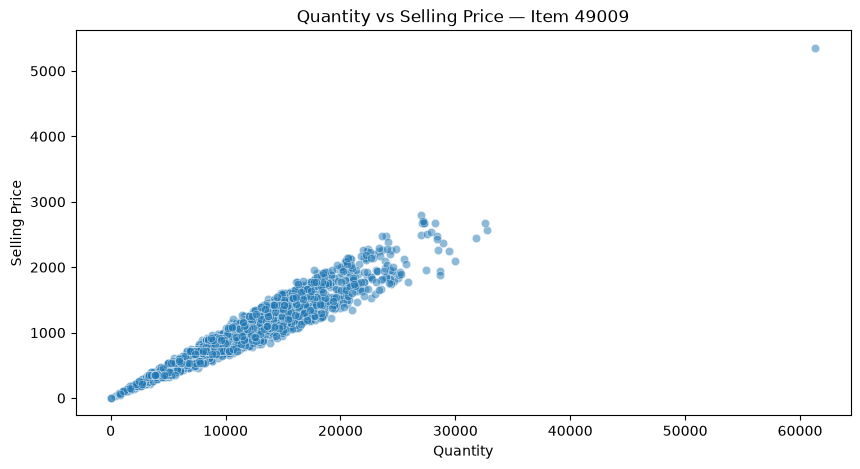

In [5]:
# Select the most frequently observed item
top_item_id = transaction_data['item_id'].value_counts().idxmax()

# Filter records for this item
single_item_data = transaction_data[
    transaction_data['item_id'] == top_item_id
].copy()

print("Selected Item ID:", top_item_id)
print("Number of Transactions:", len(single_item_data))

# Sort by quantity
single_item_data = single_item_data.sort_values(
    by='quantity'
)

# Display sample records
display(
    single_item_data[
        ['item_id', 'quantity', 'selling_price']
    ].head(20)
)

# Visualize relationship
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=single_item_data.sample(
        n=min(3000, len(single_item_data)),
        random_state=42
    ),
    x='quantity',
    y='selling_price',
    alpha=0.5
)

plt.title(f"Quantity vs Selling Price — Item {top_item_id}")
plt.xlabel("Quantity")
plt.ylabel("Selling Price")
plt.show()

In [6]:
# Discount statistical summary
discount_columns = [
    'other_discount',
    'coupon_discount'
]

for col in discount_columns:

    print(f"\n{col} Analysis")

    print(transaction_data[col].describe())

    print("\nNegative values:",
          (transaction_data[col] < 0).sum())

    print("Zero values:",
          (transaction_data[col] == 0).sum())

    print("Positive values:",
          (transaction_data[col] > 0).sum())


# Compare discount magnitudes
discount_summary = transaction_data[
    discount_columns
].abs().describe()

print("\nAbsolute Discount Summary:")
display(discount_summary)


other_discount Analysis
count    1.324566e+06
mean    -1.776871e+01
std      3.788867e+01
min     -3.120310e+03
25%     -2.315000e+01
50%     -1.780000e+00
75%      0.000000e+00
max      0.000000e+00
Name: other_discount, dtype: float64

Negative values: 671649
Zero values: 652917
Positive values: 0

coupon_discount Analysis
count    1.324566e+06
mean    -5.948983e-01
std      7.069367e+00
min     -1.992230e+03
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      0.000000e+00
Name: coupon_discount, dtype: float64

Negative values: 21286
Zero values: 1303280
Positive values: 0

Absolute Discount Summary:


,other_discount,coupon_discount
count,1.324566e+06,1.324566e+06
mean,1.776871e+01,5.948983e-01
std,3.788867e+01,7.069367e+00
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,1.780000e+00,0.000000e+00
75%,2.315000e+01,0.000000e+00
max,3.120310e+03,1.992230e+03


In [7]:
# Item-level discount analysis
item_discount_analysis = (
    transaction_data
    .groupby('item_id')
    .agg(
        transaction_count=('item_id', 'size'),
        avg_selling_price=('selling_price', 'mean'),
        avg_other_discount=('other_discount', 'mean'),
        avg_coupon_discount=('coupon_discount', 'mean'),
        coupon_discount_count=(
            'coupon_discount',
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

# Keep frequently observed items
item_discount_analysis = item_discount_analysis[
    item_discount_analysis['transaction_count'] >= 50
]

# Sort by coupon discount frequency
item_discount_analysis = item_discount_analysis.sort_values(
    by='coupon_discount_count',
    ascending=False
)

display(item_discount_analysis.head(20))

,item_id,transaction_count,avg_selling_price,avg_other_discount,avg_coupon_discount,coupon_discount_count
45499,45502,3292,177.682479,-95.820483,-5.279918,187
45536,45539,1526,216.572071,-132.112687,-7.421147,117
53518,53521,1500,170.686187,-90.500600,-4.329487,74
53514,53517,1755,158.954382,-79.671185,-3.836000,69
45575,45578,895,158.933933,-98.824983,-6.964804,61
5982,5984,212,260.863302,-71.812594,-10.173255,58
22629,22631,587,85.750460,-12.393629,-2.451584,57
14762,14764,90,79.479000,-14.488444,-10.627111,56
45524,45527,625,181.351904,-116.006192,-6.986640,50
28287,28289,869,49.740380,-2.257123,-1.166168,49


In [8]:
# Calculate provisional adjusted amount
transaction_data['adjusted_amount'] = (
    transaction_data['selling_price']
    + transaction_data['other_discount']
    + transaction_data['coupon_discount']
)

# Compare original and adjusted amounts
print("Original Selling Price Summary:")
display(transaction_data['selling_price'].describe())

print("\nAdjusted Amount Summary:")
display(transaction_data['adjusted_amount'].describe())

# Check negative adjusted amounts
print(
    "\nNegative Adjusted Amounts:",
    (transaction_data['adjusted_amount'] < 0).sum()
)

# Check zero adjusted amounts
print(
    "Zero Adjusted Amounts:",
    (transaction_data['adjusted_amount'] == 0).sum()
)

Original Selling Price Summary:


count    1.324566e+06
mean     1.146036e+02
std      1.529053e+02
min      3.600000e-01
25%      4.916000e+01
50%      7.801000e+01
75%      1.243100e+02
max      1.780964e+04
Name: selling_price, dtype: float64


Adjusted Amount Summary:


count    1.324566e+06
mean     9.624003e+01
std      1.479755e+02
min     -1.424440e+03
25%      3.526000e+01
50%      6.376000e+01
75%      1.065000e+02
max      1.602864e+04
Name: adjusted_amount, dtype: float64


Negative Adjusted Amounts: 27524
Zero Adjusted Amounts: 6442


In [9]:
# Compare original and adjusted amounts
transaction_data['discount_difference'] = (
    transaction_data['selling_price']
    - transaction_data['adjusted_amount']
)

# Check consistency
print(
    "Adjusted amount greater than selling price:",
    (
        transaction_data['adjusted_amount']
        > transaction_data['selling_price']
    ).sum()
)

print(
    "Adjusted amount equal to selling price:",
    (
        transaction_data['adjusted_amount']
        == transaction_data['selling_price']
    ).sum()
)

print(
    "Adjusted amount lower than selling price:",
    (
        transaction_data['adjusted_amount']
        < transaction_data['selling_price']
    ).sum()
)

# Display unusual records
display(
    transaction_data.loc[
        transaction_data['adjusted_amount']
        > transaction_data['selling_price'],
        [
            'customer_id',
            'item_id',
            'selling_price',
            'other_discount',
            'coupon_discount',
            'adjusted_amount'
        ]
    ].head(10)
)

Adjusted amount greater than selling price: 0
Adjusted amount equal to selling price: 645250
Adjusted amount lower than selling price: 679316


,customer_id,item_id,selling_price,other_discount,coupon_discount,adjusted_amount


In [10]:
# Calculate provisional amount per quantity
transaction_data['adjusted_amount_per_quantity'] = (
    transaction_data['adjusted_amount']
    / transaction_data['quantity'].replace(0, np.nan)
)

# Statistical summary
print("Adjusted Amount per Quantity:")
display(
    transaction_data[
        'adjusted_amount_per_quantity'
    ].describe()
)

# Correlation analysis
print("\nCorrelation Matrix:")

display(
    transaction_data[
        [
            'quantity',
            'selling_price',
            'adjusted_amount',
            'adjusted_amount_per_quantity'
        ]
    ].corr()
)

Adjusted Amount per Quantity:


count    1.324566e+06
mean     7.367204e+01
std      9.083491e+01
min     -1.424440e+03
25%      2.707000e+01
50%      5.307500e+01
75%      9.581000e+01
max      1.602864e+04
Name: adjusted_amount_per_quantity, dtype: float64


Correlation Matrix:


,quantity,selling_price,adjusted_amount,adjusted_amount_per_quantity
quantity,1.000000,0.672741,0.681000,-0.079994
selling_price,0.672741,1.000000,0.966412,0.542331
adjusted_amount,0.681000,0.966412,1.000000,0.587832
adjusted_amount_per_quantity,-0.079994,0.542331,0.587832,1.000000


In [11]:
# Load item metadata
item_data = pd.read_csv("../data/raw/item_data.csv")

# Merge category information
transaction_category = transaction_data.merge(
    item_data[['item_id', 'category']],
    on='item_id',
    how='left'
)

# Category-level analysis
category_analysis = (
    transaction_category
    .groupby('category')
    .agg(
        transaction_count=('item_id', 'size'),
        avg_quantity=('quantity', 'mean'),
        median_quantity=('quantity', 'median'),
        avg_selling_price=('selling_price', 'mean'),
        avg_adjusted_amount=('adjusted_amount', 'mean'),
        avg_amount_per_quantity=(
            'adjusted_amount_per_quantity', 'mean'
        )
    )
    .reset_index()
)

display(
    category_analysis.sort_values(
        'transaction_count',
        ascending=False
    )
)

,category,transaction_count,avg_quantity,median_quantity,avg_selling_price,avg_adjusted_amount,avg_amount_per_quantity
6,Grocery,942176,1.320702,1.0,91.521779,73.446639,62.552741
11,Pharmaceutical,155245,1.222416,1.0,147.324046,134.580870,120.272181
10,Packaged Meat,66110,1.309363,1.0,134.488465,98.641714,84.088774
9,Natural Products,52981,1.254299,1.0,86.902200,79.137473,70.362815
7,Meat,23056,1.326553,1.0,202.534326,162.632556,133.227131
2,"Dairy, Juices & Snacks",20465,1.346299,1.0,107.100653,94.151011,77.156009
1,Bakery,18218,1.376386,1.0,117.956141,107.891735,97.646758
4,Fuel,13797,10859.239472,10560.0,930.509512,899.883578,0.150828
12,Prepared Food,13069,1.081184,1.0,146.225757,135.413513,127.497206
15,Seafood,7043,1.240097,1.0,194.181481,142.206246,121.433919


In [12]:
# Category-wise correlation analysis

category_correlations = (
    transaction_category
    .groupby('category')
    .apply(
        lambda group: group['quantity'].corr(
            group['selling_price']
        )
    )
    .reset_index(name='quantity_price_correlation')
)

display(
    category_correlations.sort_values(
        'quantity_price_correlation',
        ascending=False
    )
)

,category,quantity_price_correlation
4,Fuel,0.953972
8,Miscellaneous,0.882627
18,Vegetables (cut),0.824809
17,Travel,0.590667
3,Flowers & Plants,0.584971
2,"Dairy, Juices & Snacks",0.527389
0,Alcohol,0.455599
5,Garden,0.445482
15,Seafood,0.407192
7,Meat,0.391836


In [13]:
# Candidate A: Recorded selling price
transaction_data['candidate_A'] = (
    transaction_data['selling_price']
)

# Candidate B: Discount-adjusted amount
transaction_data['candidate_B'] = (
    transaction_data['selling_price']
    + transaction_data['other_discount']
    + transaction_data['coupon_discount']
)

# Candidate C: Quantity multiplied by selling price
transaction_data['candidate_C'] = (
    transaction_data['quantity']
    * transaction_data['selling_price']
)

# Compare all three candidates
comparison = transaction_data[
    ['candidate_A', 'candidate_B', 'candidate_C']
].describe()

print("Expenditure Candidate Comparison:")
display(comparison)

# Check negative values
for col in ['candidate_A', 'candidate_B', 'candidate_C']:
    print(
        f"{col} negative values:",
        (transaction_data[col] < 0).sum()
    )

Expenditure Candidate Comparison:


,candidate_A,candidate_B,candidate_C
count,1.324566e+06,1.324566e+06,1.324566e+06
mean,1.146036e+02,9.624003e+01,1.498874e+05
std,1.529053e+02,1.479755e+02,2.087076e+06
min,3.600000e-01,-1.424440e+03,3.600000e-01
25%,4.916000e+01,3.526000e+01,5.343000e+01
50%,7.801000e+01,6.376000e+01,8.905000e+01
75%,1.243100e+02,1.065000e+02,1.424800e+02
max,1.780964e+04,1.602864e+04,7.982264e+08


candidate_A negative values: 0
candidate_B negative values: 27524
candidate_C negative values: 0


In [14]:
# Analyze adjusted amount validity by category

category_validation = (
    transaction_category
    .groupby('category')
    .agg(
        total_transactions=('adjusted_amount', 'size'),

        negative_amounts=(
            'adjusted_amount',
            lambda x: (x < 0).sum()
        ),

        zero_amounts=(
            'adjusted_amount',
            lambda x: (x == 0).sum()
        ),

        positive_amounts=(
            'adjusted_amount',
            lambda x: (x > 0).sum()
        ),

        avg_adjusted_amount=(
            'adjusted_amount', 'mean'
        )
    )
    .reset_index()
)

# Calculate negative amount percentage
category_validation['negative_percentage'] = (
    category_validation['negative_amounts']
    / category_validation['total_transactions']
) * 100

# Display results
display(
    category_validation.sort_values(
        'negative_percentage',
        ascending=False
    )
)

,category,total_transactions,negative_amounts,zero_amounts,positive_amounts,avg_adjusted_amount,negative_percentage
16,Skin & Hair Care,4868,403,78,4387,115.897005,8.278554
7,Meat,23056,946,65,22045,162.632556,4.103053
10,Packaged Meat,66110,2689,2247,61174,98.641714,4.067463
15,Seafood,7043,185,254,6604,142.206246,2.626722
6,Grocery,942176,20369,1652,920155,73.446639,2.161910
11,Pharmaceutical,155245,2396,1545,151304,134.580870,1.543367
12,Prepared Food,13069,113,29,12927,135.413513,0.864642
1,Bakery,18218,120,110,17988,107.891735,0.658689
2,"Dairy, Juices & Snacks",20465,83,19,20363,94.151011,0.405570
17,Travel,247,1,0,246,84.857895,0.404858


In [15]:
category_comparison = (
    transaction_category
    .groupby('category')
    .agg(
        avg_selling_price=('selling_price', 'mean'),
        avg_adjusted_amount=('adjusted_amount', 'mean'),
        median_selling_price=('selling_price', 'median'),
        median_adjusted_amount=('adjusted_amount', 'median')
    )
    .reset_index()
)

category_comparison['average_difference'] = (
    category_comparison['avg_selling_price']
    - category_comparison['avg_adjusted_amount']
)

display(category_comparison)

,category,avg_selling_price,avg_adjusted_amount,median_selling_price,median_adjusted_amount,average_difference
0,Alcohol,369.721176,369.721176,320.22,320.22,0.000000
1,Bakery,117.956141,107.891735,88.69,71.24,10.064406
2,"Dairy, Juices & Snacks",107.100653,94.151011,92.26,81.57,12.949642
3,Flowers & Plants,302.335243,299.202828,248.98,248.98,3.132416
4,Fuel,930.509512,899.883578,890.50,857.38,30.625934
5,Garden,339.850751,309.514407,284.25,213.36,30.336344
6,Grocery,91.521779,73.446639,71.24,56.28,18.075140
7,Meat,202.534326,162.632556,163.14,137.50,39.901770
8,Miscellaneous,678.651817,657.169931,569.92,551.04,21.481886
9,Natural Products,86.902200,79.137473,78.01,70.88,7.764728


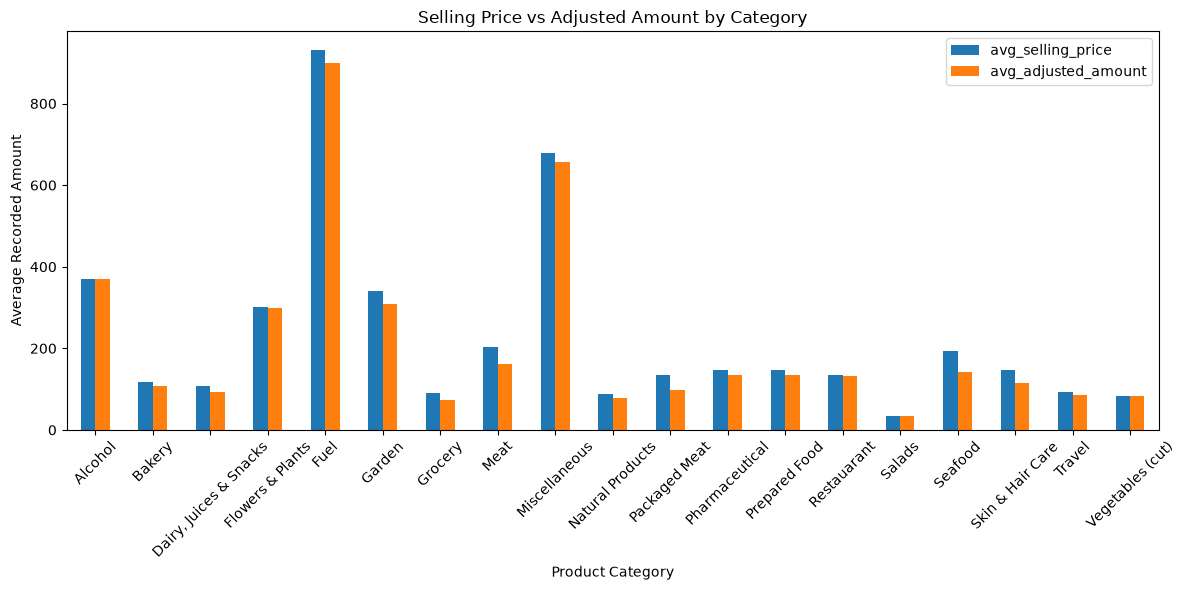

In [16]:
category_comparison.plot(
    x='category',
    y=['avg_selling_price', 'avg_adjusted_amount'],
    kind='bar',
    figsize=(12, 6)
)

plt.title('Selling Price vs Adjusted Amount by Category')
plt.xlabel('Product Category')
plt.ylabel('Average Recorded Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
# Aggregate transaction amounts by customer
customer_discount_analysis = (
    transaction_category
    .groupby('customer_id')
    .agg(
        total_transactions=('customer_id', 'size'),
        total_selling_price=('selling_price', 'sum'),
        total_adjusted_amount=('adjusted_amount', 'sum'),
        total_other_discount=('other_discount', 'sum'),
        total_coupon_discount=('coupon_discount', 'sum')
    )
    .reset_index()
)

# Calculate discount impact
customer_discount_analysis['discount_impact'] = (
    customer_discount_analysis['total_selling_price']
    - customer_discount_analysis['total_adjusted_amount']
)

# Calculate discount impact percentage
customer_discount_analysis['discount_impact_percentage'] = (
    customer_discount_analysis['discount_impact']
    / customer_discount_analysis['total_selling_price'].replace(0, np.nan)
) * 100

display(customer_discount_analysis.head(10))

,customer_id,total_transactions,total_selling_price,total_adjusted_amount,total_other_discount,total_coupon_discount,discount_impact,discount_impact_percentage
0,1,1048,98513.93,79366.70,-17030.40,-2116.83,19147.23,19.436064
1,2,419,43100.03,35798.74,-7051.95,-249.34,7301.29,16.940336
2,3,705,73050.27,54857.20,-16013.53,-2179.54,18193.07,24.904863
3,4,220,33973.22,30956.98,-2927.19,-89.05,3016.24,8.878287
4,5,792,103615.10,92707.20,-10817.07,-90.83,10907.90,10.527327
5,6,583,59508.22,52101.47,-6997.13,-409.62,7406.75,12.446600
6,7,1053,107477.03,87944.20,-18747.40,-785.43,19532.83,18.173958
7,8,1318,299482.15,261865.71,-31011.15,-6605.29,37616.44,12.560495
8,9,557,57275.87,45071.89,-11753.75,-450.23,12203.98,21.307367
9,10,491,50960.30,45323.84,-5636.46,0.00,5636.46,11.060492


In [19]:
print("Customer Discount Impact Summary:")

display(
    customer_discount_analysis[
        [
            'total_selling_price',
            'total_adjusted_amount',
            'discount_impact',
            'discount_impact_percentage'
        ]
    ].describe()
)

Customer Discount Impact Summary:


,total_selling_price,total_adjusted_amount,discount_impact,discount_impact_percentage
count,1582.000000,1582.000000,1582.000000,1582.000000
mean,95954.535841,80579.183919,15375.351922,16.981735
std,75260.501831,65568.182808,12236.760870,6.740776
min,7806.080000,3465.890000,568.840000,2.292972
25%,45327.190000,36704.605000,7039.972500,12.435158
50%,72597.885000,59453.945000,11913.890000,15.866103
75%,124123.050000,102353.552500,19779.290000,20.074962
max,583638.780000,529971.400000,109943.910000,72.860016


In [20]:
# Identify customers with coupon discounts
customer_discount_analysis['coupon_group'] = np.where(
    customer_discount_analysis['total_coupon_discount'] < 0,
    'Coupon Discount',
    'No Coupon Discount'
)

# Compare customer groups
coupon_group_analysis = (
    customer_discount_analysis
    .groupby('coupon_group')
    .agg(
        customer_count=('customer_id', 'count'),
        avg_transactions=('total_transactions', 'mean'),
        avg_selling_price=('total_selling_price', 'mean'),
        avg_adjusted_amount=('total_adjusted_amount', 'mean'),
        median_adjusted_amount=('total_adjusted_amount', 'median')
    )
    .reset_index()
)

display(coupon_group_analysis)

,coupon_group,customer_count,avg_transactions,avg_selling_price,avg_adjusted_amount,median_adjusted_amount
0,Coupon Discount,1249,926.873499,106272.288567,88818.197830,69366.79
1,No Coupon Discount,333,501.204204,57255.217057,49676.696306,41043.77


In [21]:
# Outcome feasibility assessment

outcome_assessment = pd.DataFrame({
    'Assessment Criteria': [
        'Customer-level aggregation',
        'Recorded selling price available',
        'Discount variables available',
        'Negative adjusted amounts investigated',
        'Transaction measurement verified',
        'Actual expenditure definition confirmed',
        'Causal outcome feasibility established'
    ],

    'Status': [
        'Completed',
        'Available',
        'Available',
        'Completed',
        'Partially verified',
        'Not yet confirmed',
        'Pending'
    ],

    'Observation': [
        'Transactions aggregated using customer_id',
        'selling_price is available in transaction data',
        'Both discount columns are available',
        'Negative and zero amounts were investigated',
        'Measurement conventions still require documentation',
        'Original expenditure calculation remains uncertain',
        'Further validation is required'
    ]
})

display(outcome_assessment)

,Assessment Criteria,Status,Observation
0,Customer-level aggregation,Completed,Transactions aggregated using customer_id
1,Recorded selling price available,Available,selling_price is available in transaction data
2,Discount variables available,Available,Both discount columns are available
3,Negative adjusted amounts investigated,Completed,Negative and zero amounts were investigated
4,Transaction measurement verified,Partially verified,Measurement conventions still require document...
5,Actual expenditure definition confirmed,Not yet confirmed,Original expenditure calculation remains uncer...
6,Causal outcome feasibility established,Pending,Further validation is required


# Day 20 — Final Outcome Feasibility Assessment

## 1. Work Completed

- Investigated original transaction variables.
- Examined selling price and quantity relationships.
- Investigated discount measurement patterns.
- Compared recorded and discount-adjusted amounts.
- Analyzed transaction patterns across product categories.
- Examined customer-level discount impact.
- Compared customers with and without recorded coupon discounts.
- Assessed customer-level outcome feasibility.

## 2. Key Findings

1. Customer-level transaction aggregation is technically possible.
2. Selling price and discount variables are available.
3. Transaction quantities exhibit different patterns across product categories.
4. Discount-adjusted amounts can be calculated mathematically.
5. The exact measurement conventions require further verification.
6. Observed coupon discounts do not establish campaign assignment or exposure.

## 3. Outcome Feasibility Decision

**Preliminary Decision: PARTIALLY FEASIBLE**

Customer-level spending candidates can be constructed from the available transaction data.

However, the actual expenditure definition and measurement conventions have not been sufficiently verified.

Therefore, neither expenditure candidate should yet be treated as a validated causal outcome.

## 4. Remaining Limitations

- Exact meaning of quantity requires verification.
- Selling price measurement convention remains uncertain.
- Discount calculation requires original documentation.
- Actual campaign exposure remains unresolved.
- Treatment assignment mechanism remains unresolved.
- Causal identification assumptions require further investigation.

## 5. Research Recommendation

Further investigate the original dataset documentation and validate transaction measurement conventions.

Do not proceed directly to Double Machine Learning estimation until the treatment, outcome, and identification strategy are defensible.

## 6. Conclusion

Day 20 established that customer-level expenditure analysis is technically possible, but a scientifically validated expenditure outcome has not yet been established.

The project can proceed to further causal research design and identification assessment, subject to these limitations.

In [23]:
day20_assessment = pd.DataFrame({
    'Assessment Criteria': [
        'Customer-level aggregation',
        'Recorded selling price available',
        'Discount variables available',
        'Negative adjusted amounts investigated',
        'Transaction measurement verified',
        'Actual expenditure definition confirmed',
        'Causal outcome feasibility established'
    ],
    'Status': [
        'Completed',
        'Available',
        'Available',
        'Completed',
        'Partially verified',
        'Not yet confirmed',
        'Pending'
    ],
    'Observation': [
        'Transactions can be aggregated using customer_id',
        'selling_price is available in transaction data',
        'Both discount columns are available',
        'Negative and zero adjusted amounts were investigated',
        'Measurement conventions still require original documentation',
        'Actual expenditure calculation remains uncertain',
        'Further treatment, outcome, and identification validation is required'
    ]
})

display(day20_assessment)

,Assessment Criteria,Status,Observation
0,Customer-level aggregation,Completed,Transactions can be aggregated using customer_id
1,Recorded selling price available,Available,selling_price is available in transaction data
2,Discount variables available,Available,Both discount columns are available
3,Negative adjusted amounts investigated,Completed,Negative and zero adjusted amounts were invest...
4,Transaction measurement verified,Partially verified,Measurement conventions still require original...
5,Actual expenditure definition confirmed,Not yet confirmed,Actual expenditure calculation remains uncertain
6,Causal outcome feasibility established,Pending,"Further treatment, outcome, and identification..."
